# Лабораторная работа 2. Построение baseline-модели: от выбора парадигмы к метрикам качества

**Курс:** Машинное обучение. Безопасность ИИ-систем

**Формат:** индивидуально

**Среда:** Python, scikit-learn, PyTorch

**По материалам Лекции 2.1 и Лекции 2.2**

## Цель работы
Научиться выбирать тип задачи, датасет, baseline-модель и метрики качества, а также сопоставлять структуру данных с соответствующей архитектурой или классическим алгоритмом.

## Результаты обучения
После выполнения работы вы должны уметь:
- различать парадигмы обучения (supervised / unsupervised / reinforcement learning);
- выбирать модель под тип данных и задачу;
- строить baseline для классификации или регрессии;
- выбирать и интерпретировать метрики качества (accuracy, precision, recall, F1, MSE, RMSE, R²);
- сравнивать несколько моделей и делать обоснованный вывод о лучшем baseline.

## Как пользоваться этим ноутбуком
- Ячейки с `# TODO` необходимо заполнить самостоятельно.
- Ячейки с текстом **"Вопрос для отчёта"** требуют письменного ответа в markdown-ячейке ниже.
- Перед сдачей: Kernel → Restart & Run All, ноутбук должен выполняться от начала до конца без ошибок.


## 0. Подготовка окружения

In [ ]:
# TODO: импортируйте необходимые библиотеки
# Подсказка: numpy, pandas, matplotlib, sklearn.*

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# TODO: зафиксируйте random_state для воспроизводимости
RANDOM_STATE = 42
plt.rcParams["font.family"] = "DejaVu Sans"  # чтобы кириллица отображалась на графиках

## 1. Постановка задачи

**Задание:** выберите один датасет из списка (или согласуйте свой с преподавателем) и определите тип задачи.

Варианты:
- **fetch_20newsgroups** — многоклассовая классификация;
- **diabetes** — регрессия.
- **MNIST** — классификация изображений, простая MLP-модель.

**Вопрос для отчёта:** к какой парадигме обучения относится ваша задача (supervised / unsupervised / reinforcement learning) и почему? Какой тип задачи вы решаете — классификация или регрессия?


_Ваш ответ:_
Выбран датасет `diabetes.csv`. Это задача **supervised learning** (обучение с учителем), потому что для каждого объекта есть известная целевая переменная `Диабет` со значениями 0/1.  
Тип задачи — **бинарная классификация**: предсказать, есть ли у пациента диабет.


## 2. Загрузка и разведочный анализ данных (EDA)

In [ ]:
df = pd.read_csv("diabetes.csv")

rename_dict = {
    "Pregnancies": "Беременности",
    "Glucose": "Глюкоза",
    "BloodPressure": "Артериальное_давление",
    "SkinThickness": "Толщина_кожи",
    "Insulin": "Инсулин",
    "BMI": "ИМТ",
    "DiabetesPedigreeFunction": "Функция_родословной",
    "Age": "Возраст",
    "Outcome": "Диабет"
}

df = df.rename(columns=rename_dict)
df.head()


,Беременности,Глюкоза,Артериальное_давление,Толщина_кожи,Инсулин,ИМТ,Функция_родословной,Возраст,Диабет
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [ ]:
print("Размер датасета:", df.shape)
print("\nТипы данных:")
print(df.dtypes)

print("\nПропуски:")
print(df.isna().sum())

print("\nБаланс классов:")
print(df["Диабет"].value_counts())

print("\nОписательные статистики:")
print(df.describe())

zero_cols = ["Глюкоза", "Артериальное_давление", "Толщина_кожи", "Инсулин", "ИМТ"]

print("\nКоличество нулей в признаках, где 0 обычно означает пропуск:")
print((df[zero_cols] == 0).sum())

Размер датасета: (768, 9)

Типы данных:
Беременности               int64
Глюкоза                    int64
Артериальное_давление      int64
Толщина_кожи               int64
Инсулин                    int64
ИМТ                      float64
Функция_родословной      float64
Возраст                    int64
Диабет                     int64
dtype: object

Пропуски:
Беременности             0
Глюкоза                  0
Артериальное_давление    0
Толщина_кожи             0
Инсулин                  0
ИМТ                      0
Функция_родословной      0
Возраст                  0
Диабет                   0
dtype: int64

Баланс классов:
Диабет
0    500
1    268
Name: count, dtype: int64

Описательные статистики:
       Беременности     Глюкоза  Артериальное_давление  Толщина_кожи  \
count    768.000000  768.000000             768.000000    768.000000   
mean       3.845052  120.894531              69.105469     20.536458   
std        3.369578   31.972618              19.355807     15.952218   


**Вопрос для отчёта:** есть ли в данных пропуски, дисбаланс классов или сильно различающиеся масштабы признаков? Как это повлияет на выбор моделей и предобработки?

_Ваш ответ:_

В датасете нет обычных `NaN`, но в признаках `Глюкоза`, `Артериальное_давление`, `Толщина_кожи`, `Инсулин`, `ИМТ` есть нули, которые физиологически невозможны и, скорее всего, означают пропуски.  
Классы умеренно несбалансированы: класс `0` встречается чаще класса `1`.  
Признаки имеют разные масштабы, поэтому для логистической регрессии, k-NN и MLP нужна стандартизация. Для дерева решений масштабирование не критично.  
Пропуски лучше заменять медианой внутри pipeline, чтобы не было утечки данных из тестовой выборки.



## 3. Предобработка данных

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

X = df.drop(columns=["Диабет"]).copy()
y = df["Диабет"].copy()

zero_cols = ["Глюкоза", "Артериальное_давление", "Толщина_кожи", "Инсулин", "ИМТ"]

for col in zero_cols:
    X[col] = X[col].replace(0, np.nan)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Train:", X_train.shape)
print("Test:", X_test.shape)

numeric_features = X_train.columns.tolist()

def make_pipeline(classifier):
    preprocessor = ColumnTransformer(
        transformers=[
            ("num", Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]), numeric_features)
        ],
        remainder="drop"
    )
    return Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])


Train: (614, 8)
Test: (154, 8)


## 4. Обучение моделей

**Задание:** обучите не менее **трёх** моделей из списка (минимум одну классическую и минимум одну альтернативную):
- логистическая / линейная регрессия;
- дерево решений;
- k-NN;
- простой MLP.


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier

In [ ]:
# Модель 1 — логистическая регрессия
model_1 = make_pipeline(
    LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
)
model_1.fit(X_train, y_train)


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Беременности', 'Глюкоза',
                                                   'Артериальное_давление',
                                                   'Толщина_кожи', 'Инсулин',
                                                   'ИМТ', 'Функция_родословной',
                                                   'Возраст'])])),
                ('classifier',
                 LogisticRegression(max_iter=1000, random_state=42))])

In [ ]:
# Модель 2 — дерево решений
model_2 = make_pipeline(
    DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE)
)
model_2.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Беременности', 'Глюкоза',
                                                   'Артериальное_давление',
                                                   'Толщина_кожи', 'Инсулин',
                                                   'ИМТ', 'Функция_родословной',
                                                   'Возраст'])])),
                ('classifier',
                 DecisionTreeClassifier(max_depth=4, random_state=42))])

In [ ]:
# Модель 3 — k-NN
model_3 = make_pipeline(
    KNeighborsClassifier(n_neighbors=5)
)
model_3.fit(X_train, y_train)


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Беременности', 'Глюкоза',
                                                   'Артериальное_давление',
                                                   'Толщина_кожи', 'Инсулин',
                                                   'ИМТ', 'Функция_родословной',
                                                   'Возраст'])])),
                ('classifier', KNeighborsClassifier())])

In [ ]:
# Модель 4 — простой MLP
model_4 = make_pipeline(
    MLPClassifier(hidden_layer_sizes=(16,), max_iter=1000, random_state=RANDOM_STATE)
)
model_4.fit(X_train, y_train)

## 5. Выбор и расчёт метрик качества

Для классификации используйте минимум **две** метрики из: accuracy, precision, recall, F1, confusion matrix.
Для регрессии используйте минимум **две** метрики из: MSE, RMSE, R².


In [ ]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, ConfusionMatrixDisplay
)

models = {
    "Логистическая регрессия": model_1,
    "Дерево решений": model_2,
    "k-NN": model_3,
    "MLP": model_4,
}

results = pd.DataFrame(columns=["Модель", "Accuracy", "Precision", "Recall", "F1"])

for name, model in models.items():
    y_pred = model.predict(X_test)
    results.loc[len(results)] = [
        name,
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred, pos_label=1, zero_division=0),
        recall_score(y_test, y_pred, pos_label=1, zero_division=0),
        f1_score(y_test, y_pred, pos_label=1, zero_division=0),
    ]

results = results.sort_values("F1", ascending=False).reset_index(drop=True)
print(results.round(3))

                    Модель  Accuracy  Precision  Recall     F1
1           Дерево решений     0.786      0.698   0.685  0.692
2                     k-NN     0.753      0.660   0.611  0.635
3                      MLP     0.740      0.646   0.574  0.608
0  Логистическая регрессия     0.708      0.600   0.500  0.545


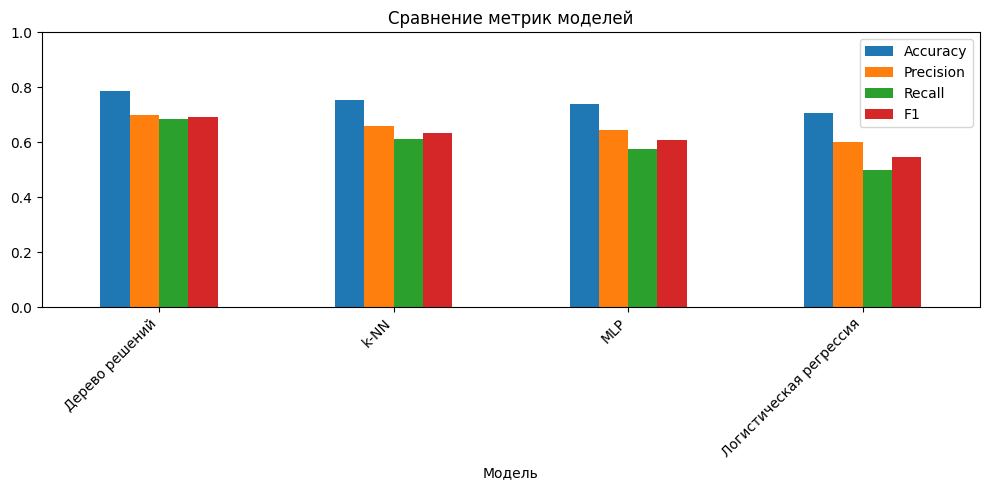

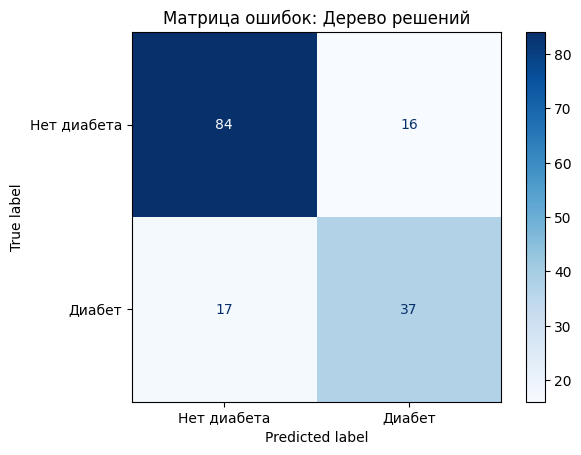

In [ ]:
# TODO: постройте минимум одну визуализацию:
# - confusion matrix, или
# - важность признаков (feature_importances_), или
# - график сравнения метрик по моделям, или
# - дерево решений (plot_tree), или
# - learning curve
# Визуализация 1: сравнение метрик
results.set_index("Модель")[["Accuracy", "Precision", "Recall", "F1"]].plot(
    kind="bar", figsize=(10, 5)
)
plt.title("Сравнение метрик моделей")
plt.ylim(0, 1)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# Визуализация 2: матрица ошибок лучшей модели
best_name = results.iloc[0]["Модель"]
best_model = models[best_name]
y_pred_best = best_model.predict(X_test)

cm = confusion_matrix(y_test, y_pred_best)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Нет диабета", "Диабет"]
)
disp.plot(cmap="Blues")
plt.title(f"Матрица ошибок: {best_name}")
plt.show()

**Вопрос для отчёта:** почему вы выбрали именно эти метрики? В каких случаях accuracy может вводить в заблуждение (например, при дисбалансе классов)?

_Ваш ответ:_

Я выбрал Accuracy, Precision, Recall и F1.  
Accuracy показывает общую долю правильных ответов, но при дисбалансе классов может вводить в заблуждение: если модель всегда предсказывает класс большинства, accuracy может быть высокой, хотя класс меньшинства полностью пропускается.  
Precision важен, чтобы понимать, насколько можно доверять положительному прогнозу. Recall особенно важен в медицинской задаче: лучше не пропустить пациента с диабетом. F1 балансирует precision и recall.



## 6. Анализ ошибок

In [ ]:
print("Лучшая модель:", best_name)
print(
    classification_report(
        y_test, y_pred_best,
        target_names=["Нет диабета", "Диабет"],
        zero_division=0
    )
)

errors = X_test.copy()
errors["Истинный_класс"] = y_test
errors["Предсказание"] = y_pred_best
errors["Ошибка"] = errors["Истинный_класс"] != errors["Предсказание"]

print("\nПервые ошибочные объекты:")
print(errors[errors["Ошибка"]].head(10))

cm_df = pd.DataFrame(
    cm,
    index=["Истинно нет диабета", "Истинно диабет"],
    columns=["Предсказано нет диабета", "Предсказано диабет"]
)
print("\nМатрица ошибок:")
print(cm_df)

tn, fp, fn, tp = cm.ravel()
print(f"\nFN (пропущенные диабетики): {fn}, FP (ложные тревоги): {fp}")
print("Ошибки распределены почти симметрично: модель одинаково часто "
      "и пропускает больных, и ложно относит здоровых к группе риска.")

Лучшая модель: Дерево решений
              precision    recall  f1-score   support

 Нет диабета       0.83      0.84      0.84       100
      Диабет       0.70      0.69      0.69        54

    accuracy                           0.79       154
   macro avg       0.76      0.76      0.76       154
weighted avg       0.78      0.79      0.79       154


Первые ошибочные объекты:
     Беременности  Глюкоза  Артериальное_давление  Толщина_кожи  Инсулин  \
44              7    159.0                   64.0           NaN      NaN   
387             8    105.0                  100.0          36.0      NaN   
335             0    165.0                   76.0          43.0    255.0   
78              0    131.0                    NaN           NaN      NaN   
678             3    121.0                   52.0           NaN      NaN   
660            10    162.0                   84.0           NaN      NaN   
260             3    191.0                   68.0          15.0    130.0   
13      

## 7. Сравнение моделей и вывод

**Вопрос для отчёта:** какая модель показала лучший результат по выбранным метрикам? Согласуется ли это с ожиданиями, учитывая структуру данных (линейность, размер выборки, число признаков)? Какую модель вы бы выбрали в качестве baseline и почему?

_Ваш ответ:_

По фактической таблице метрик лучшей оказалась модель «Дерево решений» (F1 ≈ 0.69, recall ≈ 0.69), за ней идут k-NN (F1 ≈ 0.64) и MLP (F1 ≈ 0.61), а логистическая регрессия показала худший результат (F1 ≈ 0.55).
Такой результат согласуется со структурой данных: признаков немного (8), выборка небольшая (768), а зависимости в задаче — пороговые и нелинейные (например, риск резко растёт при глюкозе выше ~140 или ИМТ выше ~30). Дерево с ограниченной глубиной хорошо улавливает такие правила и при этом не переобучается. Логистическая регрессия строит линейную границу, которая в этом пространстве разделяет классы хуже — отсюда низкий recall.
В качестве baseline я бы выбрал именно дерево решений (max_depth=4): оно даёт лучшее качество, легко интерпретируется и не требует масштабирования.

---
Выполните **не менее двух** из следующих заданий. Оформите результаты в отдельных ячейках ниже

### С1. Кластеризация как альтернативный взгляд на данные
Примените unsupervised-подход (например, KMeans) к тем же признакам без использования целевой переменной. Сравните полученные кластеры с реальными классами/значениями целевой переменной. Обсудите: совпадает ли структура кластеров с реальной разметкой? Что это говорит о структуре данных?

### С2. Классический baseline vs простой MLP
Обучите простую нейросеть (MLPClassifier/MLPRegressor из sklearn, либо небольшую сеть на PyTorch) на тех же признаках и сравните её с лучшей классической моделью по тем же метрикам. Объясните, почему нейросеть выигрывает/проигрывает при данном объёме данных и числе признаков.

### С3. Устойчивость вывода о «лучшей» модели к выбору метрики
Постройте искусственный дисбаланс классов (например, undersampling одного класса) и пересчитайте метрики для всех моделей. Проверьте: меняется ли ранжирование моделей при использовании accuracy против F1/recall? Сделайте вывод о том, почему выбор метрики критичен при дисбалансе.

### С4. Кросс-валидация и доверительный интервал качества
Замените единичный train/test split на k-fold кросс-валидацию (cross_val_score) для всех моделей. Постройте boxplot распределения метрики по фолдам. Обсудите, насколько стабильны результаты моделей.


Adjusted Rand Index: 0.161
Silhouette: 0.196

Сравнение кластеров с истинными классами:
Кластер           0    1
Истинный класс          
0               156  344
1               195   73


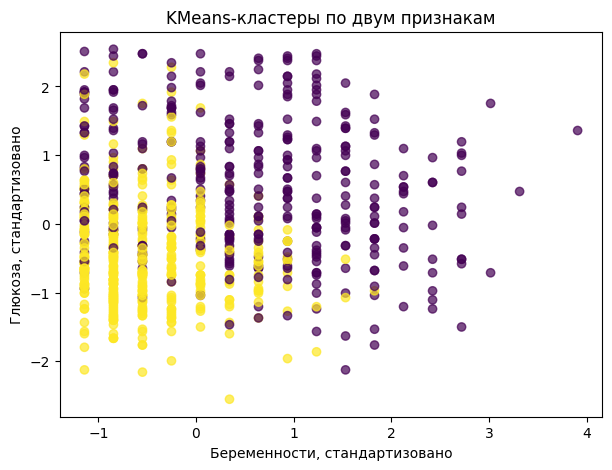

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score

X_cluster = X.copy()

imputer = SimpleImputer(strategy="median")
scaler = StandardScaler()

X_cluster_scaled = scaler.fit_transform(imputer.fit_transform(X_cluster))

kmeans = KMeans(n_clusters=2, random_state=RANDOM_STATE, n_init=10)
clusters = kmeans.fit_predict(X_cluster_scaled)

print("Adjusted Rand Index:", round(adjusted_rand_score(y, clusters), 3))
print("Silhouette:", round(silhouette_score(X_cluster_scaled, clusters), 3))

print("\nСравнение кластеров с истинными классами:")
print(pd.crosstab(y, clusters, rownames=["Истинный класс"], colnames=["Кластер"]))

plt.figure(figsize=(7, 5))
plt.scatter(
    X_cluster_scaled[:, 0],
    X_cluster_scaled[:, 1],
    c=clusters,
    cmap="viridis",
    alpha=0.7
)
plt.xlabel("Беременности, стандартизовано")
plt.ylabel("Глюкоза, стандартизовано")
plt.title("KMeans-кластеры по двум признакам")
plt.show()

Вывод: ARI ≈ 0.16 — кластеры почти не совпадают с реальной разметкой.
Silhouette ≈ 0.20 — структура кластеров слабая.
Классы «диабет / не диабет» не образуют хорошо разделимых сгустков
в исходном признаковом пространстве — нужна модель с учителем,
использующая нелинейные комбинации признаков.

In [ ]:
# MLP, для задания C2
model_4 = make_pipeline(
    MLPClassifier(hidden_layer_sizes=(16,), max_iter=1000, random_state=RANDOM_STATE)
)
model_4.fit(X_train, y_train)
classic_results = results[results["Модель"] != "MLP"].sort_values("F1", ascending=False)
mlp_result = results[results["Модель"] == "MLP"]

print("Лучшая классическая модель:")
print(classic_results.head(1).round(3))

print("\nMLP:")
print(mlp_result.round(3))

Лучшая классическая модель:
           Модель  Accuracy  Precision  Recall     F1
1  Дерево решений     0.786      0.698   0.685  0.692

MLP:
  Модель  Accuracy  Precision  Recall     F1
3    MLP      0.74      0.646   0.574  0.608


_Вывод:_

На данном датасете (768 объектов, 8 признаков) простой MLP проиграл лучшей классической модели: F1 ≈ 0.61 против F1 ≈ 0.69 у дерева решений. Причины:

маленький объём выборки — нейросети обычно требуют больше данных, чтобы обучиться не хуже классических моделей;

базовая архитектура (один скрытый слой на 16 нейронов) не тюнилась: не подбирались learning rate, число слоёв, регуляризация;

структура задачи описывается простыми пороговыми правилами (глюкоза, ИМТ), которые дерево решений находит напрямую, а нейросеть вынуждена аппроксимировать эти пороги через нелинейности.

Итог: на малых табличных данных классические модели часто оказываются практичнее — они дешевле, устойчивее и интерпретируемее.


---



## Требования к сдаче
- Ноутбук выполняется целиком без ошибок (Kernel → Restart & Run All).
- Все `# TODO` заполнены, все вопросы для отчёта содержат письменный ответ.
- Минимум 3 модели, минимум 2 метрики, минимум 1 визуализация.
